In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

#Load the Iris dataset
from sklearn.datasets import load_iris
iris=load_iris()

#Create feature dataframe and target series
import seaborn as sns
df=sns.load_dataset('iris')

X=df.iloc[:, :-1]
y=iris.target

#Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)


[Text(0.5416666666666666, 0.9285714285714286, 'x[2] <= 2.45\ngini = 0.666\nsamples = 100\nvalue = [31, 35, 34]'),
 Text(0.4583333333333333, 0.7857142857142857, 'gini = 0.0\nsamples = 31\nvalue = [31, 0, 0]'),
 Text(0.5, 0.8571428571428572, 'True  '),
 Text(0.625, 0.7857142857142857, 'x[3] <= 1.75\ngini = 0.5\nsamples = 69\nvalue = [0, 35, 34]'),
 Text(0.5833333333333333, 0.8571428571428572, '  False'),
 Text(0.4166666666666667, 0.6428571428571429, 'x[2] <= 5.35\ngini = 0.188\nsamples = 38\nvalue = [0, 34, 4]'),
 Text(0.3333333333333333, 0.5, 'x[3] <= 1.65\ngini = 0.105\nsamples = 36\nvalue = [0, 34, 2]'),
 Text(0.16666666666666666, 0.35714285714285715, 'x[2] <= 4.95\ngini = 0.057\nsamples = 34\nvalue = [0, 33, 1]'),
 Text(0.08333333333333333, 0.21428571428571427, 'gini = 0.0\nsamples = 32\nvalue = [0, 32, 0]'),
 Text(0.25, 0.21428571428571427, 'x[2] <= 5.05\ngini = 0.5\nsamples = 2\nvalue = [0, 1, 1]'),
 Text(0.16666666666666666, 0.07142857142857142, 'gini = 0.0\nsamples = 1\nvalue = [

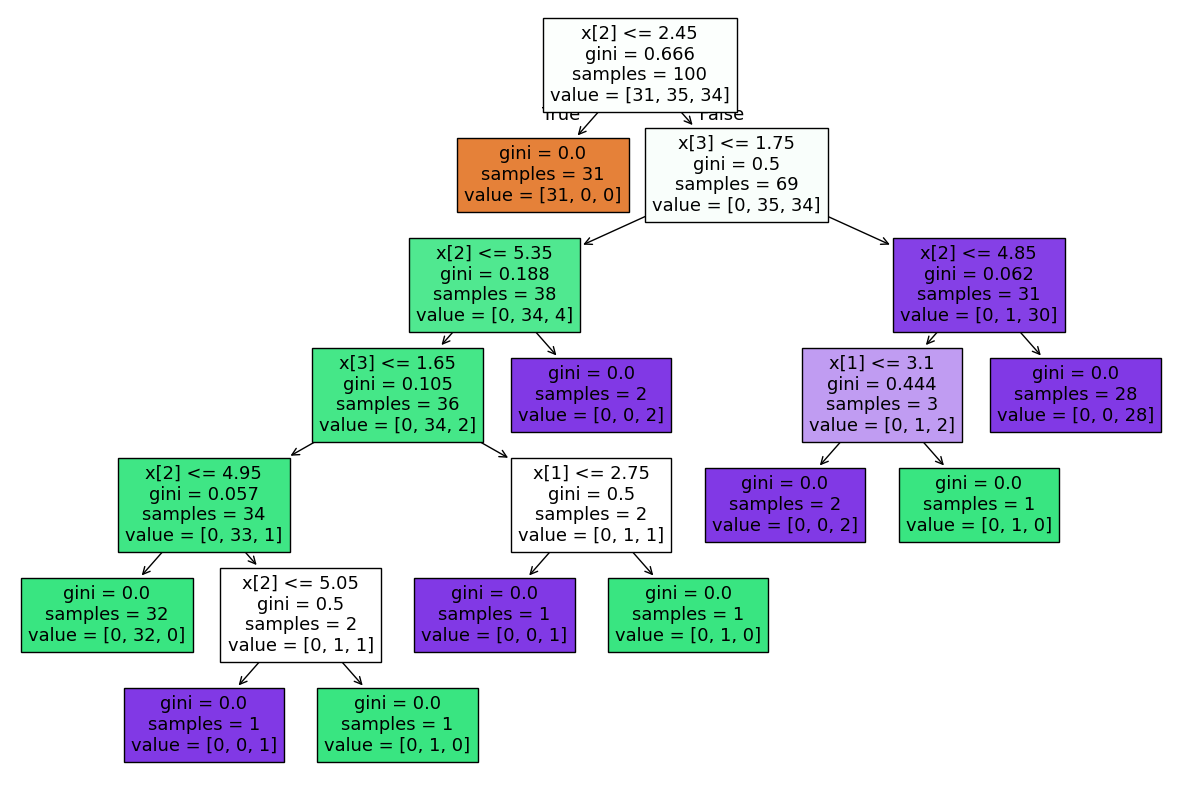

In [2]:
#Fit an initial unpruned Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier
classifier=DecisionTreeClassifier()
classifier.fit(X_train,y_train)

#Initial tree visualization
from sklearn import tree
plt.figure(figsize=(15,10))
tree.plot_tree(classifier,filled=True)

In [3]:
#Define the parameter grid for pre-pruning
parameter={
    'criterion':['gini', 'entropy', 'log_loss'],
    'splitter':['best', 'random'],
    'max_depth':[1, 2, 3, 4, 5],
    'max_features':['auto', 'sqrt', 'log2']
}
#Initialize GridSearchCV with the Decision Tree
from sklearn.model_selection import GridSearchCV
cv=GridSearchCV(classifier,param_grid=parameter,cv=5,scoring='accuracy')

#Fit the grid search to training data
cv.fit(X_train,y_train)

#Retrieve the best hyperparameters determined by cross-validation
print("Best parameters found: ",cv.best_params_)


Best parameters found:  {'criterion': 'gini', 'max_depth': 3, 'max_features': 'log2', 'splitter': 'best'}


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
150 fits failed out of a total of 450.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
150 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.12/dist-packages/sklearn/util

Accuracy Score: 0.98

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      0.94      0.97        16
           2       0.94      1.00      0.97        15

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50



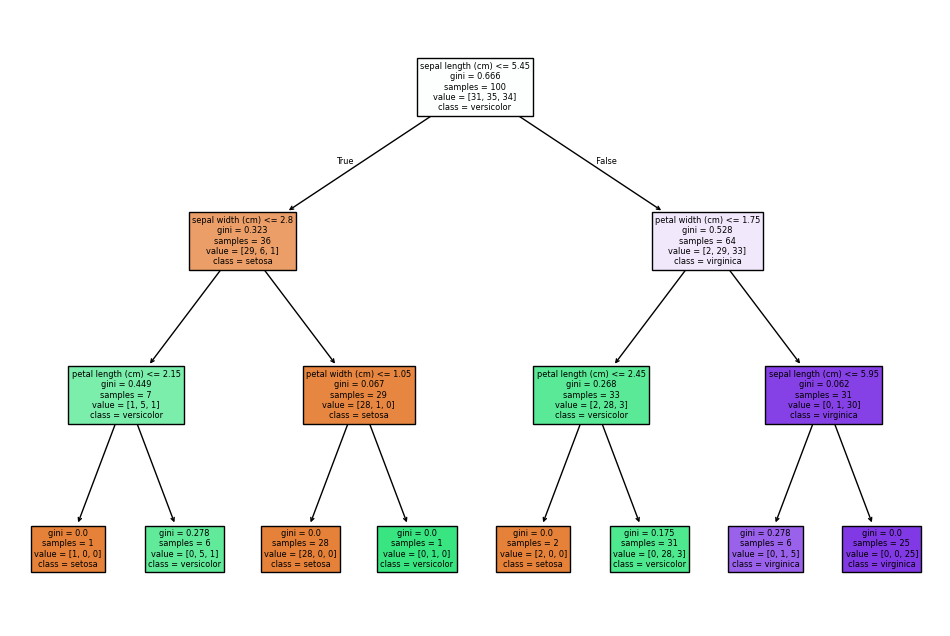

In [4]:
#Predict using the optimized model
y_pred=cv.predict(X_test)

#Check performance metrics
from sklearn.metrics import accuracy_score,classification_report
print(f"Accuracy Score: {accuracy_score(y_pred, y_test)}")
print("\nClassification Report:\n",classification_report(y_pred,y_test))
#Visualize the pre-pruned (optimized) decision tree
best_tree=cv.best_estimator_
plt.figure(figsize=(12, 8))
tree.plot_tree(best_tree, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)
plt.show()
